# Week 5: Support Vector Machines, Kernels, and Regularization
**Victor Vasquez Gil** | Boston University | Integrated Capstone

## 1. Research Question

Can an SVM identify charged-off loans better than logistic regression when both models use the same training data?

This week returns to the main credit-risk question in my capstone. I use borrower and loan information recorded around the time of issuance. `Charged Off` is 1 and `Fully Paid` is 0. I leave out other statuses so that unfinished loans are not counted as fully paid.

Week 4 showed me why accuracy alone can be misleading when most loans are fully paid. I keep ROC-AUC and average precision for comparing the rankings, then use precision, recall, and the error counts to understand what happens at the selected threshold. A flagged loan would need further review.

In [1]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import sys, json, time, warnings, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display, HTML, Markdown
from threadpoolctl import threadpool_limits
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, GridSearchCV, RandomizedSearchCV, cross_validate
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, log_loss, brier_score_loss,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve, precision_recall_curve)

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | sklearn {sklearn.__version__}")

from sklearn.svm import SVC

Python 3.14.2 | pandas 3.0.6 | sklearn 1.9.1


In [3]:
SEED = 42
SAMPLE_SIZE = 50_000
CHUNK_SIZE = 25_000
EXPECTED_SOURCE_ROWS = 2_260_701  # Accepted-loans version 3; prevents accidental use of a partial export.
CV_FOLDS = 3
N_JOBS = 1
MODEL_TRAIN_SIZE = 8_000  # Weeks 5 and 6 use the same stratified training subset for a fair comparison.
DATA_PATH = None  # Or Path(r"/full/path/to/accepted_2007_to_2018Q4.csv.gz")
DATASET_URL = "https://www.kaggle.com/datasets/wordsforthewise/lending-club"
DATASET_VERSION = 3
OUTPUT_DIR = Path("week5_outputs")
CACHE_DIR = Path("capstone_cache")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)
thread_limit = threadpool_limits(limits=1)
NUMERIC = ["loan_amnt", "annual_inc", "dti", "fico_range_low", "open_acc",
           "pub_rec", "revol_bal", "revol_util", "total_acc", "delinq_2yrs", "inq_last_6mths"]
CATEGORICAL = ["term", "home_ownership", "purpose", "emp_length"]
FEATURES = NUMERIC + CATEGORICAL
BLUE, TEAL, ORANGE, GRAY, PURPLE = "#315F91", "#137C8B", "#B85C20", "#6B7280", "#8064A2"
sns.set_theme(style="whitegrid", rc={"figure.dpi":120,"font.family":"DejaVu Sans",
    "axes.spines.top":False,"axes.spines.right":False,"grid.alpha":0.25})

In [4]:
def show_table(frame, decimals=3):
    formatters = {c: (lambda x: f"{x:,.{decimals}f}") for c in frame.select_dtypes(include="floating").columns}
    display(HTML('<style>.cap-table{border-collapse:collapse;font-family:system-ui;font-size:13px;}'
        '.cap-table th{background:#172B4D;color:white;padding:8px;}'
        '.cap-table td{padding:8px;border-bottom:1px solid #ddd;}'
        '.cap-table tr:nth-child(even){background:#f3f6f8;}</style>' +
        frame.to_html(index=False, border=0, classes="cap-table", formatters=formatters)))

def finish(fig, name):
    fig.savefig(OUTPUT_DIR / f"{name}.png", dpi=180, bbox_inches="tight", facecolor="white")
    plt.show()

def clean_number(s):
    return pd.to_numeric(s.astype("string").str.strip().str.replace(",", "", regex=False)
        .str.replace("%", "", regex=False), errors="coerce").astype(float).replace([np.inf, -np.inf], np.nan)

def locate_source(configured):
    if configured is not None:
        path = Path(configured).expanduser()
        if path.is_file(): return path
        raise FileNotFoundError(f"DATA_PATH does not exist: {path}. No download was attempted.")
    roots = [Path.home()/".cache/kagglehub/datasets/wordsforthewise/lending-club/versions/3",
             Path.cwd()/"data", Path.cwd(), Path.home()/"Downloads"]
    # Prefer the known version-3 cache and its compressed file when both copies exist.
    for root in roots:
        if not root.is_dir(): continue
        candidates = []
        for name in ["accepted_2007_to_2018Q4.csv.gz", "accepted_2007_to_2018Q4.csv"]:
            candidates.extend(p for p in root.rglob(name) if p.is_file())
        if candidates:
            return sorted(set(candidates), key=lambda p: (not p.name.endswith(".gz"), str(p)))[0]
    raise FileNotFoundError("No local accepted-loans file found. Set DATA_PATH to your existing version-3 CSV/CSV.GZ. No download is included.")

def sample_loans(path, cohort):
    fingerprint = {"resolved_path":str(path.resolve()),"bytes":path.stat().st_size,
        "mtime_ns":path.stat().st_mtime_ns,"cohort":cohort,"seed":SEED,
        "sample_size":SAMPLE_SIZE,"chunk_size":CHUNK_SIZE,"algorithm":"priority-v1"}
    key = hashlib.sha256(json.dumps(fingerprint, sort_keys=True).encode()).hexdigest()[:16]
    cache_file = CACHE_DIR/f"{cohort}_{key}.csv.gz"
    info_file = CACHE_DIR/f"{cohort}_{key}.json"
    if cache_file.is_file() and info_file.is_file():
        info = json.loads(info_file.read_text())
        sample = pd.read_csv(cache_file, dtype="string")
        sample["source_row"] = pd.to_numeric(sample["source_row"]).astype("int64")
        if info["rows_scanned"] != EXPECTED_SOURCE_ROWS:
            raise ValueError("Cached source row count does not match the expected version-3 file.")
        if len(sample) != min(SAMPLE_SIZE, info["eligible_rows"]):
            raise ValueError("Incomplete sample cache: remove these two cache files and rerun.")
        print("Reusing the local sample cache.")
        return sample, info
    header = pd.read_csv(path, nrows=0)
    required = FEATURES + (["int_rate"] if cohort=="pricing" else ["loan_status"])
    absent = sorted(set(required)-set(header.columns))
    if absent: raise ValueError(f"Required columns missing: {absent}")
    requested = list(dict.fromkeys(FEATURES+["int_rate","loan_status","id","member_id","issue_d"]))
    requested = [c for c in requested if c in header.columns]
    rng = np.random.default_rng(SEED)
    sample = None
    scanned = eligible = 0
    for batch, chunk in enumerate(pd.read_csv(path, usecols=requested, dtype="string",
                                             chunksize=CHUNK_SIZE, low_memory=False),1):
        chunk["source_row"] = np.arange(scanned, scanned+len(chunk))
        scanned += len(chunk)
        if cohort=="pricing":
            rate = clean_number(chunk["int_rate"])
            chunk = chunk.loc[rate.gt(0) & rate.lt(100)].copy()
        else:
            chunk["loan_status"] = chunk["loan_status"].str.strip()
            chunk = chunk.loc[chunk["loan_status"].isin(["Fully Paid","Charged Off"])].copy()
        eligible += len(chunk)
        if len(chunk):
            chunk["_priority"] = rng.random(len(chunk))
            sample = chunk if sample is None else pd.concat([sample,chunk],ignore_index=True)
            sample = sample.nsmallest(SAMPLE_SIZE,"_priority")
        if batch%20==0: print(f"Scanned {scanned:,} source rows...")
    if scanned != EXPECTED_SOURCE_ROWS:
        raise ValueError(f"Scanned {scanned:,} rows; expected {EXPECTED_SOURCE_ROWS:,} for version 3. Check for a partial/different file before continuing.")
    if sample is None or len(sample)<100: raise ValueError("Too few eligible rows.")
    sample = sample.drop(columns="_priority").reset_index(drop=True)
    info = {**fingerprint,"rows_scanned":scanned,"eligible_rows":eligible,"sample_rows":len(sample)}
    sample.to_csv(cache_file,index=False,compression="gzip")
    info_file.write_text(json.dumps(info,indent=2))
    return sample,info

def prepare_xy(loans, cohort):
    for key in ["id","member_id"]:
        if key not in loans: continue
        ids = loans[key].astype("string").str.strip().replace("",pd.NA).dropna()
        if len(ids) and ids.duplicated().any():
            raise ValueError(f"Repeated {key}: resolve duplicate loans or use borrower-group splits before running the analysis.")
    if "member_id" not in loans or loans["member_id"].isna().all():
        print("No usable borrower ID: repeated-borrower dependence remains a limitation.")
    X = loans[FEATURES].copy()
    for col in NUMERIC: X[col] = clean_number(X[col])
    for col in CATEGORICAL:
        values = X[col].astype("string").str.strip().replace("",pd.NA)
        X[col] = values.astype(object).where(values.notna(),np.nan)
    y = (clean_number(loans["int_rate"]).rename("interest_rate") if cohort=="pricing" else
         loans["loan_status"].str.strip().map({"Fully Paid":0,"Charged Off":1}).astype(int).rename("charged_off"))
    assert X.index.equals(y.index) and y.notna().all()
    return X,y

def make_preprocessor(columns=None, numeric_scale=True, scale_all=False):
    columns = FEATURES if columns is None else list(columns)
    transforms=[]
    for i,col in enumerate(columns):
        if col in NUMERIC:
            steps=[("impute",SimpleImputer(strategy="median",keep_empty_features=True))]
            if numeric_scale: steps.append(("scale",StandardScaler()))
        else:
            steps=[("impute",SimpleImputer(strategy="constant",fill_value="Missing",keep_empty_features=True)),
                   ("encode",OneHotEncoder(drop="first",handle_unknown="ignore",sparse_output=False))]
        transforms.append((f"g{i:02d}",Pipeline(steps),[col]))
    prepare=ColumnTransformer(transforms,remainder="drop",verbose_feature_names_out=True)
    return Pipeline([("columns",prepare),("scale",StandardScaler())]) if scale_all else prepare

def rmse(y,pred): return float(np.sqrt(mean_squared_error(y,np.asarray(pred).ravel())))

def regression_metrics(name, model, Xfit,yfit,Xhold,yhold):
    pred=np.asarray(model.predict(Xhold)).ravel()
    return {"Model":name,"Training RMSE":rmse(yfit,model.predict(Xfit)),"Test RMSE":rmse(yhold,pred),
            "Test MAE":mean_absolute_error(yhold,pred),"Test R2":r2_score(yhold,pred)}

def ranking_score(model,X):
    if hasattr(model,"decision_function"): return np.asarray(model.decision_function(X)).ravel()
    return model.predict_proba(X)[:,1]

def choose_threshold(target,scores,default):
    grid=np.unique(np.r_[default,np.quantile(scores,np.linspace(0.01,0.99,99))])
    table=pd.DataFrame([{"Threshold":float(t),"Precision":precision_score(target,scores>=t,zero_division=0),
        "Recall":recall_score(target,scores>=t,zero_division=0),"F1":f1_score(target,scores>=t,zero_division=0)} for t in grid])
    chosen=float(table.sort_values(["F1","Threshold"],ascending=[False,False]).iloc[0]["Threshold"])
    return chosen,table

def classification_metrics(name,target,scores,threshold,rule):
    pred=np.asarray(scores)>=threshold
    tn,fp,fn,tp=confusion_matrix(target,pred,labels=[0,1]).ravel()
    return {"Model":name,"Rule":rule,"Threshold":float(threshold),"Accuracy":accuracy_score(target,pred),
        "Balanced accuracy":balanced_accuracy_score(target,pred),"Precision":precision_score(target,pred,zero_division=0),
        "Recall":recall_score(target,pred,zero_division=0),"F1":f1_score(target,pred,zero_division=0),
        "ROC-AUC":roc_auc_score(target,scores),"Average precision":average_precision_score(target,scores),
        "Flagged share":float(pred.mean()),"TP":int(tp),"FP":int(fp),"FN":int(fn),"TN":int(tn)}

def plot_ranking(target,score_dict,filename):
    fig,axes=plt.subplots(1,2,figsize=(12,4.5),layout="constrained")
    for (name,scores),color in zip(score_dict.items(),[TEAL,BLUE,ORANGE,PURPLE,GRAY]):
        fpr,tpr,_=roc_curve(target,scores)
        precision,recall,_=precision_recall_curve(target,scores)
        axes[0].plot(fpr,tpr,color=color,label=f"{name} ({roc_auc_score(target,scores):.3f})")
        axes[1].step(recall,precision,where="post",color=color,label=f"{name} ({average_precision_score(target,scores):.3f})")
    axes[0].plot([0,1],[0,1],ls="--",color=GRAY)
    axes[1].axhline(float(np.mean(target)),ls="--",color=GRAY,label=f"Prevalence ({np.mean(target):.3f})")
    axes[0].set(title="Test ROC curves (legend = AUC)",xlabel="False positive rate",ylabel="Recall",xlim=(0,1),ylim=(0,1.02))
    axes[1].set(title="Test precision-recall curves (legend = AP)",xlabel="Recall",ylabel="Precision",xlim=(0,1),ylim=(0,1.02))
    for ax in axes: ax.legend(fontsize=8)
    finish(fig,filename)

def plot_confusions(target,scores,default,chosen,name,filename):
    fig,axes=plt.subplots(1,2,figsize=(11,4.4),layout="constrained")
    for ax,t,label in [(axes[0],default,"Default"),(axes[1],chosen,"Validation-selected")]:
        ConfusionMatrixDisplay.from_predictions(target,scores>=t,labels=[0,1],display_labels=["Fully paid","Charged off"],
            values_format=",d",cmap="Blues",colorbar=False,ax=ax)
        ax.set_title(f"{label}: {t:.3f}");ax.grid(False)
    fig.suptitle(f"{name}: the cost of changing the threshold",fontweight="bold")
    finish(fig,filename)

## 2. Data and a Fair Comparison

I use the existing local accepted-loans file from the [Lending Club dataset on Kaggle](https://www.kaggle.com/datasets/wordsforthewise/lending-club). This link is the source reference; the notebook does not download the dataset.

I keep the same 50,000-loan outcome sample and 60/20/20 split from Week 4 when the file and settings match. That gives me 30,000 loans in the training pool, 10,000 for validation, and 10,000 for testing. The sampling uses seed 42 and reads the source file in batches of 25,000 rows.

Kernel SVMs can take a long time to fit, so I use a fixed, stratified sample of **8,000 training loans**. The models in this notebook and Week 6 use those same rows. I leave the remaining training loans unused for this comparison.

I also fit logistic regression on these 8,000 loans, using standardization and `C=10` from Week 4. This gives me a baseline trained on the same amount of data. The original Week 4 model used 30,000 training loans, so its saved score is not a direct comparison here.

I keep the same 15 predictors. I leave out interest rate, grade, subgrade, installment, later payments, recoveries, and later credit information to stay consistent with the earlier classification analysis.

The test split was already used in Week 4. These results help me compare models on the same historical loans, but I still need a separate test on later loans to check performance over time.

In [6]:
DATA_PATH=locate_source(DATA_PATH)
loans,source_info=sample_loans(DATA_PATH,"outcome")
X,y=prepare_xy(loans,"outcome")
X_dev,X_test,y_dev,y_test=train_test_split(X,y,test_size=0.20,stratify=y,random_state=SEED)
X_train,X_val,y_train,y_val=train_test_split(X_dev,y_dev,test_size=0.25,stratify=y_dev,random_state=SEED)
if len(X_train)>MODEL_TRAIN_SIZE:
    fit_indices,_=train_test_split(X_train.index,train_size=MODEL_TRAIN_SIZE,stratify=y_train,random_state=SEED)
    X_fit,y_fit=X_train.loc[fit_indices],y_train.loc[fit_indices]
else:
    X_fit,y_fit=X_train.copy(),y_train.copy()
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)
assert y_fit.value_counts().min()>=CV_FOLDS
cv_splits=list(StratifiedKFold(n_splits=CV_FOLDS,shuffle=True,random_state=SEED).split(X_fit,y_fit))
manifest=loans[["source_row"]].copy();manifest["split"]="training pool not used"
manifest.loc[X_fit.index,"split"]="model training / CV"
manifest.loc[X_val.index,"split"]="validation / thresholds"
manifest.loc[X_test.index,"split"]="test"
manifest.to_csv(OUTPUT_DIR/"split_manifest.csv",index=False)
split_table=pd.DataFrame([{"Split":name,"Loans":len(target),"Charged-off share":float(target.mean())}
    for name,target in [("Training pool",y_train),("Model training (subset of pool)",y_fit),
                        ("Validation",y_val),("Test",y_test)]])
show_table(split_table)
print(f"{len(X_train)-len(X_fit):,} training-pool loans are unused; they are not added to validation or test.")

Scanned 500,000 source rows...
Scanned 1,000,000 source rows...
Scanned 1,500,000 source rows...
Scanned 2,000,000 source rows...
No usable borrower ID: repeated-borrower dependence remains a limitation.


Split,Loans,Charged-off share
Training pool,30000,0.199
Model training (subset of pool),8000,0.199
Validation,10000,0.199
Test,10000,0.199


22,000 training-pool loans are unused; they are not added to validation or test.


## 3. Check the Training Sample

I check the class balance, missing values, and overlap in FICO scores before fitting the models. Missing numeric values are filled with the training median. Missing categories get their own value before one-hot encoding.

Numeric features are standardized inside each CV training fold, while the category indicators stay as 0s and 1s, as in Week 4. Scaling matters because the SVM uses distances and inner products. A balance measured in dollars should not have extra influence just because its numbers are much larger than a FICO score. Scaling changes the units; it does not remove outliers or make every feature equally useful.

Feature,Missing (%)
emp_length,5.80
revol_util,0.05
loan_amnt,0.00
fico_range_low,0.00
open_acc,0.00
annual_inc,0.00


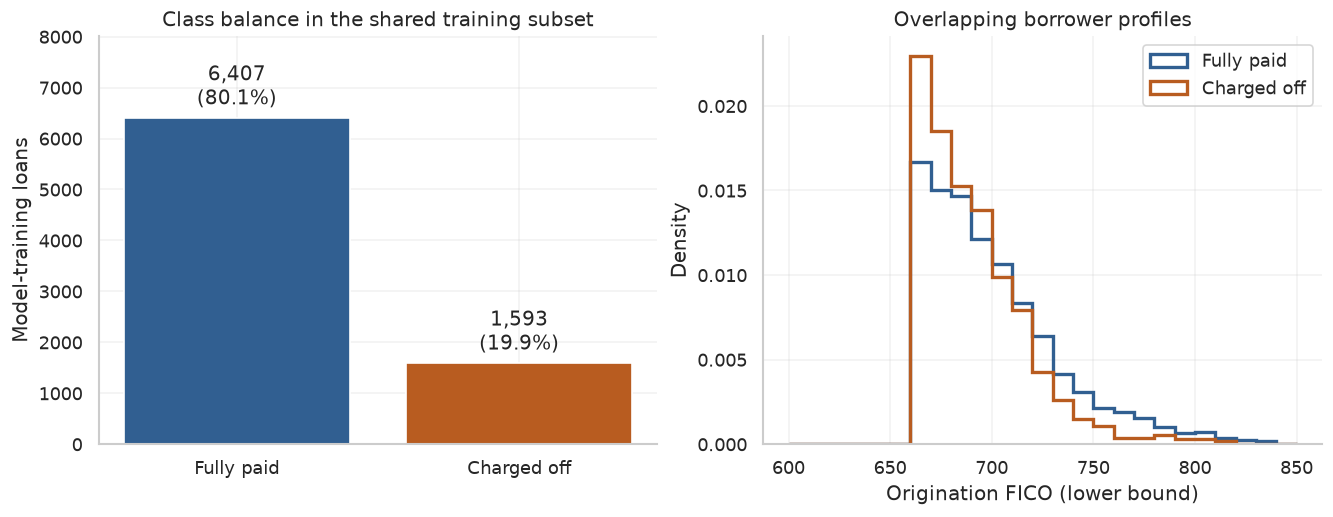

Charged-off loans make up **19.9%** of the model-training data. Predicting Fully Paid for every loan would be **80.1%** accurate and catch none of the charged-off loans. That is why I use ranking metrics and show precision and recall separately.

In [7]:
missing=X_fit.isna().mean().mul(100).rename("Missing (%)").rename_axis("Feature").reset_index().sort_values("Missing (%)",ascending=False)
show_table(missing.head(6),2)
fig,axes=plt.subplots(1,2,figsize=(11,4.2),layout="constrained")
counts=y_fit.value_counts().reindex([0,1])
bars=axes[0].bar(["Fully paid","Charged off"],counts,color=[BLUE,ORANGE])
axes[0].bar_label(bars,labels=[f"{v:,}\n({v/len(y_fit):.1%})" for v in counts],padding=4)
axes[0].set(ylim=(0,counts.max()*1.25),ylabel="Model-training loans",title="Class balance in the shared training subset")
for label,color,value in [("Fully paid",BLUE,0),("Charged off",ORANGE,1)]:
    axes[1].hist(X_fit.loc[y_fit.eq(value),"fico_range_low"].dropna(),bins=np.arange(600,856,10),density=True,
                 histtype="step",lw=2,color=color,label=label)
axes[1].set(xlabel="Origination FICO (lower bound)",ylabel="Density",title="Overlapping borrower profiles")
axes[1].legend()
finish(fig,"figure_1_training_eda")
display(Markdown(f"Charged-off loans make up **{y_fit.mean():.1%}** of the model-training data. "
    f"Predicting Fully Paid for every loan would be **{1-y_fit.mean():.1%}** accurate and catch none of the charged-off loans. "
    "That is why I use ranking metrics and show precision and recall separately."))

## 4. What the SVM is Doing

An SVM looks for a boundary between the two classes while trying to leave a wide margin around it. It also allows some loans to fall inside that margin or on the wrong side of the boundary. Since fully paid and charged-off loans can have similar borrower profiles, I do not expect a perfect separation.

The parameter **C** controls the trade-off. A smaller C allows more margin violations and puts more weight on regularization. A larger C penalizes those violations more heavily. Fitting the training loans more closely does not guarantee better results on other loans.

I compare these settings:

| Kernel | What it allows | Settings tested |
| :--- | :--- | :--- |
| Linear | A straight boundary in the encoded feature space | C = 0.1, 1, 10 |
| Polynomial | Powers and interactions between features | C = 0.1, 1; degree = 2, 3 |
| RBF | Curved boundaries based on similarity between loans | C = 0.1, 1, 10; gamma = scale, 0.01 |

The polynomial kernel is $K(x,z)=(\gamma x^Tz+r)^d$. I keep `coef0`, or $r$, at 1 and `gamma` at `scale` in that search. The RBF kernel is $K(x,z)=\exp(-\gamma\|x-z\|^2)$. A larger gamma makes similarity more local, which can create a more detailed boundary. With `gamma="scale"`, the value is calculated from the transformed training data in each fit.

The **kernel trick** lets the model work with relationships in a larger feature space without creating every extra feature column. For example, with two inputs:

$$\phi(x)=(x_1^2,\sqrt{2}x_1x_2,x_2^2)$$

Taking the inner product after this transformation gives $\phi(x)^T\phi(z)=(x^Tz)^2$. The calculation below checks that relationship. The RBF kernel also corresponds to an inner product, but in an implicit feature space with infinitely many dimensions.

The **support vectors** are the training observations that determine the fitted boundary. With a soft margin, they can sit on the margin, inside it, or on the wrong side of the boundary.

In [8]:
# A small algebra check, not a simulated Lending Club finding.
x=np.array([2.,3.]);z=np.array([-1.,4.])
def phi(v): return np.array([v[0]**2,np.sqrt(2)*v[0]*v[1],v[1]**2])
show_table(pd.DataFrame({"Calculation":["Squared original dot product","Dot product after feature map"],
                         "Value":[float((x@z)**2),float(phi(x)@phi(z))]}))
assert np.isclose((x@z)**2,phi(x)@phi(z))

Calculation,Value
Squared original dot product,100.000
Dot product after feature map,100.000


## 5. Tune on Training Folds Only

I use three stratified CV folds to compare the SVM settings by mean ROC-AUC. I also look at average precision, training scores, fit time, support-vector counts, and whether the fitting process converged. Small differences between CV scores need to be considered alongside the variation across folds.

The SVM returns a **decision score**, not a probability of charge-off. Its sign indicates the side of the fitted boundary, and the default classification threshold is zero. I use `probability=False`, so I am not adding a probability-calibration step. I can use these scores for ROC-AUC and average precision, but I do not treat them as probabilities for log loss or Brier scores.

I set an iteration limit to keep the fitting time manageable. If a setting fails to converge in any CV fold, I record the result but do not allow it to win. If the best eligible setting fails when fitted on all 8,000 training loans, I try the next eligible setting within that kernel family. These choices use training results only.

CV: {'kernel': 'linear', 'C': 0.1}


/tmp/ipykernel_9250/2078455587.py:19: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  if not issubclass(warning.category,ConvergenceWarning): warnings.warn(str(warning.message),warning.category)
/tmp/ipykernel_9250/2078455587.py:19: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  if not issubclass(warning.category,ConvergenceWarning): warnings.warn(str(warning.message),warning.category)
/tmp/ipykernel_9250/2078455587.py:19: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  if not issubclass(warning.category,ConvergenceWarning): warnings.warn(str(warning.message),warn

CV: {'kernel': 'linear', 'C': 1.0}


/tmp/ipykernel_9250/2078455587.py:19: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  if not issubclass(warning.category,ConvergenceWarning): warnings.warn(str(warning.message),warning.category)
/tmp/ipykernel_9250/2078455587.py:19: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  if not issubclass(warning.category,ConvergenceWarning): warnings.warn(str(warning.message),warning.category)
/tmp/ipykernel_9250/2078455587.py:19: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  if not issubclass(warning.category,ConvergenceWarning): warnings.warn(str(warning.message),warn

CV: {'kernel': 'linear', 'C': 10.0}


/tmp/ipykernel_9250/2078455587.py:19: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  if not issubclass(warning.category,ConvergenceWarning): warnings.warn(str(warning.message),warning.category)
/tmp/ipykernel_9250/2078455587.py:19: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  if not issubclass(warning.category,ConvergenceWarning): warnings.warn(str(warning.message),warning.category)
/tmp/ipykernel_9250/2078455587.py:19: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  if not issubclass(warning.category,ConvergenceWarning): warnings.warn(str(warning.message),warn

... (22 outputs left out)

Full fit did not converge; skipping {'kernel': 'poly', 'C': 0.1, 'degree': 3, 'gamma': 'scale', 'coef0': 1.0}
No converged configuration retained for poly


/tmp/ipykernel_9250/2078455587.py:19: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  if not issubclass(warning.category,ConvergenceWarning): warnings.warn(str(warning.message),warning.category)
/tmp/ipykernel_9250/2078455587.py:75: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  for warning in benchmark_warnings: warnings.warn(str(warning.message),warning.category)


Model,CV ROC-AUC,CV AP,Support vectors,Support share
Linear SVM,0.6110,0.2828,3450,0.4313
RBF SVM,0.6159,0.3093,4254,0.5317


Matched logistic: CV AUC 0.6794; CV AP 0.3512
SVM selected before validation/test evaluation: RBF SVM {'kernel': 'rbf', 'C': 1.0, 'gamma': 'scale'}


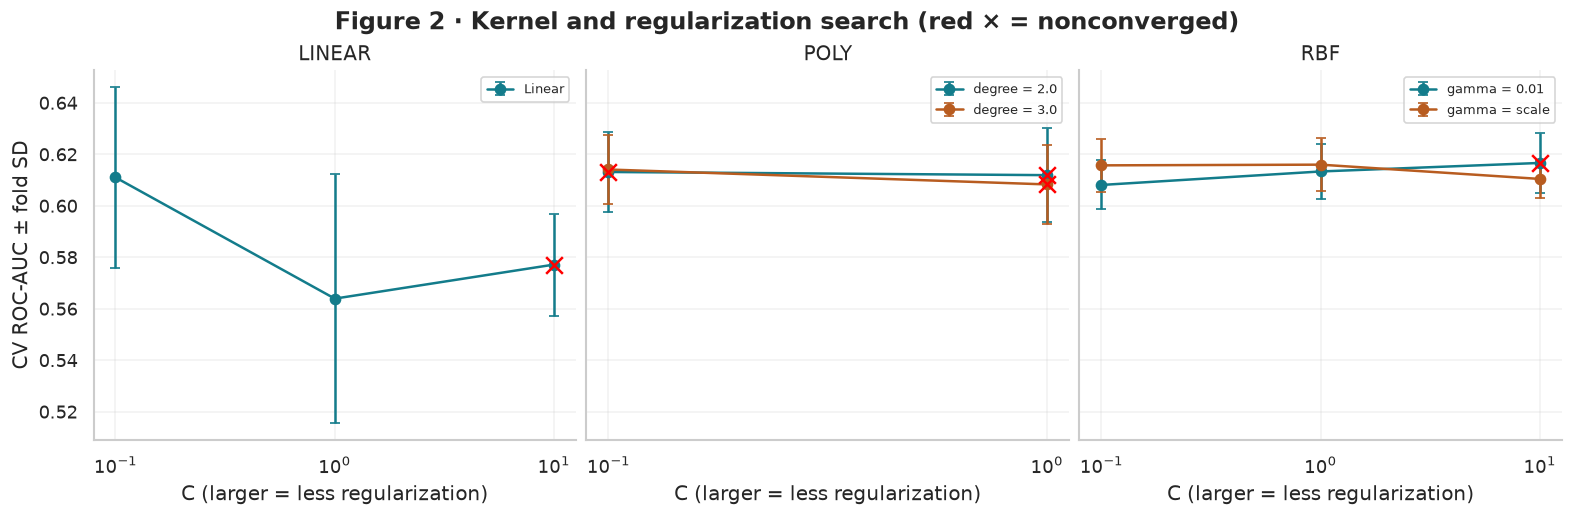

In [9]:
configurations=[]
for C in [.1,1.,10.]: configurations.append({"kernel":"linear","C":C})
for degree in [2,3]:
    for C in [.1,1.]: configurations.append({"kernel":"poly","C":C,"degree":degree,"gamma":"scale","coef0":1.})
for gamma in ["scale",.01]:
    for C in [.1,1.,10.]: configurations.append({"kernel":"rbf","C":C,"gamma":gamma})

def svm_pipeline(parameters):
    return Pipeline([("prepare",make_preprocessor()),
        ("model",SVC(**parameters,probability=False,class_weight=None,cache_size=512,max_iter=50_000,random_state=SEED))])

def fit_checked(model,A,target):
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always",ConvergenceWarning)
        model.fit(A,target)
    convergence=sum(issubclass(w.category,ConvergenceWarning) for w in caught)
    # Keep other warning types visible; do not silently hide data/encoding warnings.
    for warning in caught:
        if not issubclass(warning.category,ConvergenceWarning): warnings.warn(str(warning.message),warning.category)
    status=int(getattr(model.named_steps["model"],"fit_status_",0))
    return model,bool(convergence or status)

cv_rows=[]
for config_id,parameters in enumerate(configurations):
    fold_rows=[]
    print("CV:",parameters,flush=True)
    for train_pos,valid_pos in cv_splits:
        start=time.perf_counter()
        model,failed=fit_checked(svm_pipeline(parameters),X_fit.iloc[train_pos],y_fit.iloc[train_pos])
        elapsed=time.perf_counter()-start
        score=model.decision_function(X_fit.iloc[valid_pos])
        train_score=model.decision_function(X_fit.iloc[train_pos])
        fold_rows.append({"auc":roc_auc_score(y_fit.iloc[valid_pos],score),
            "ap":average_precision_score(y_fit.iloc[valid_pos],score),
            "train_auc":roc_auc_score(y_fit.iloc[train_pos],train_score),"seconds":elapsed,
            "support":len(model.named_steps["model"].support_),"failed":int(failed)})
    folds=pd.DataFrame(fold_rows)
    cv_rows.append({"Config":config_id,"Kernel":parameters["kernel"],"C":parameters["C"],
        "Degree":parameters.get("degree",np.nan),"Gamma":str(parameters.get("gamma","not used")),
        "CV ROC-AUC":folds.auc.mean(),"Fold SD":folds.auc.std(ddof=1),"CV AP":folds.ap.mean(),
        "CV training AUC":folds.train_auc.mean(),"Mean fit seconds":folds.seconds.mean(),
        "Mean support vectors":folds.support.mean(),"Nonconverged folds":int(folds.failed.sum())})
cv_results=pd.DataFrame(cv_rows)
show_table(cv_results.sort_values("CV ROC-AUC",ascending=False),4)
cv_results.to_csv(OUTPUT_DIR/"svm_cv_results.csv",index=False)

fitted={};chosen_rows=[];chosen_parameters={}
for kernel in ["linear","poly","rbf"]:
    ranked=cv_results.loc[cv_results.Kernel.eq(kernel)&cv_results["Nonconverged folds"].eq(0)].sort_values("CV ROC-AUC",ascending=False)
    for _,row in ranked.iterrows():
        parameters=configurations[int(row.Config)]
        model,failed=fit_checked(svm_pipeline(parameters),X_fit,y_fit)
        if failed:
            print("Full fit did not converge; skipping",parameters)
            continue
        name={"linear":"Linear SVM","poly":"Polynomial SVM","rbf":"RBF SVM"}[kernel]
        fitted[name]=model;chosen_parameters[name]=parameters
        chosen_rows.append({"Model":name,"CV ROC-AUC":float(row["CV ROC-AUC"]),
            "CV AP":float(row["CV AP"]),"Support vectors":len(model.named_steps["model"].support_),
            "Support share":len(model.named_steps["model"].support_)/len(y_fit)})
        break
    else:
        print("No converged configuration retained for",kernel)
if not fitted: raise RuntimeError("No SVM converged. Revisit scaling/iteration limits using training data; do not select from failed fits.")
svm_selection=pd.DataFrame(chosen_rows)
selected_name=svm_selection.sort_values("CV ROC-AUC",ascending=False).iloc[0].Model

logistic=Pipeline([("prepare",make_preprocessor()),("model",LogisticRegression(C=10,max_iter=5000,solver="lbfgs",random_state=SEED))])
with warnings.catch_warnings(record=True) as benchmark_warnings:
    warnings.simplefilter("always",ConvergenceWarning)
    logistic_cv=cross_validate(logistic,X_fit,y_fit,cv=cv_splits,scoring={"auc":"roc_auc","ap":"average_precision"},
        n_jobs=N_JOBS,error_score="raise")
if any(issubclass(w.category,ConvergenceWarning) for w in benchmark_warnings):
    raise RuntimeError("The logistic benchmark did not converge in CV; resolve using training data before comparing.")
for warning in benchmark_warnings: warnings.warn(str(warning.message),warning.category)
fitted["Matched logistic"],logistic_failed=fit_checked(logistic,X_fit,y_fit)
if logistic_failed: raise RuntimeError("The logistic benchmark did not converge; resolve on training data before comparing.")
show_table(svm_selection,4)
print(f"Matched logistic: CV AUC {logistic_cv['test_auc'].mean():.4f}; CV AP {logistic_cv['test_ap'].mean():.4f}")
print("SVM selected before validation/test evaluation:",selected_name,chosen_parameters[selected_name])
svm_selection.to_csv(OUTPUT_DIR/"selected_kernel_models.csv",index=False)

fig,axes=plt.subplots(1,3,figsize=(13,4.2),layout="constrained",sharey=True)
for ax,kernel in zip(axes,["linear","poly","rbf"]):
    rows=cv_results.loc[cv_results.Kernel.eq(kernel)]
    grouping=[("linear",rows)] if kernel=="linear" else list(rows.groupby("Degree" if kernel=="poly" else "Gamma"))
    for j,(group,part) in enumerate(grouping):
        part=part.sort_values("C")
        label="Linear" if kernel=="linear" else f"{'degree' if kernel=='poly' else 'gamma'} = {group}"
        ax.errorbar(part.C,part["CV ROC-AUC"],yerr=part["Fold SD"],fmt="o-",capsize=3,color=[TEAL,ORANGE][j%2],label=label)
        bad=part.loc[part["Nonconverged folds"].gt(0)]
        ax.scatter(bad.C,bad["CV ROC-AUC"],marker="x",s=100,color="red",zorder=6)
    ax.set_xscale("log");ax.set(title=kernel.upper(),xlabel="C (larger = less regularization)")
    ax.legend(fontsize=8)
axes[0].set_ylabel("CV ROC-AUC ± fold SD")
fig.suptitle("Figure 2 · Kernel and regularization search (red × = nonconverged)",fontweight="bold")
finish(fig,"figure_2_kernel_regularization")

## 6. Make the Kernel Idea Visible

The next plot uses FICO and DTI so I can see how the different kernels draw a boundary. It uses at most 1,200 real training loans and fixed settings. It is a separate illustration; the final model comparison uses all 15 predictors.

The solid line marks a decision score of zero. The dashed lines show scores of -1 and +1 when those levels fall within the plot. For nonlinear kernels, those curves do not represent equal distances in the original FICO and DTI units. The outlined points are support vectors.

The overlap between the two outcomes shows why these two features alone do not clearly separate the classes. A more curved boundary does not, by itself, show that the model will predict other loans better.

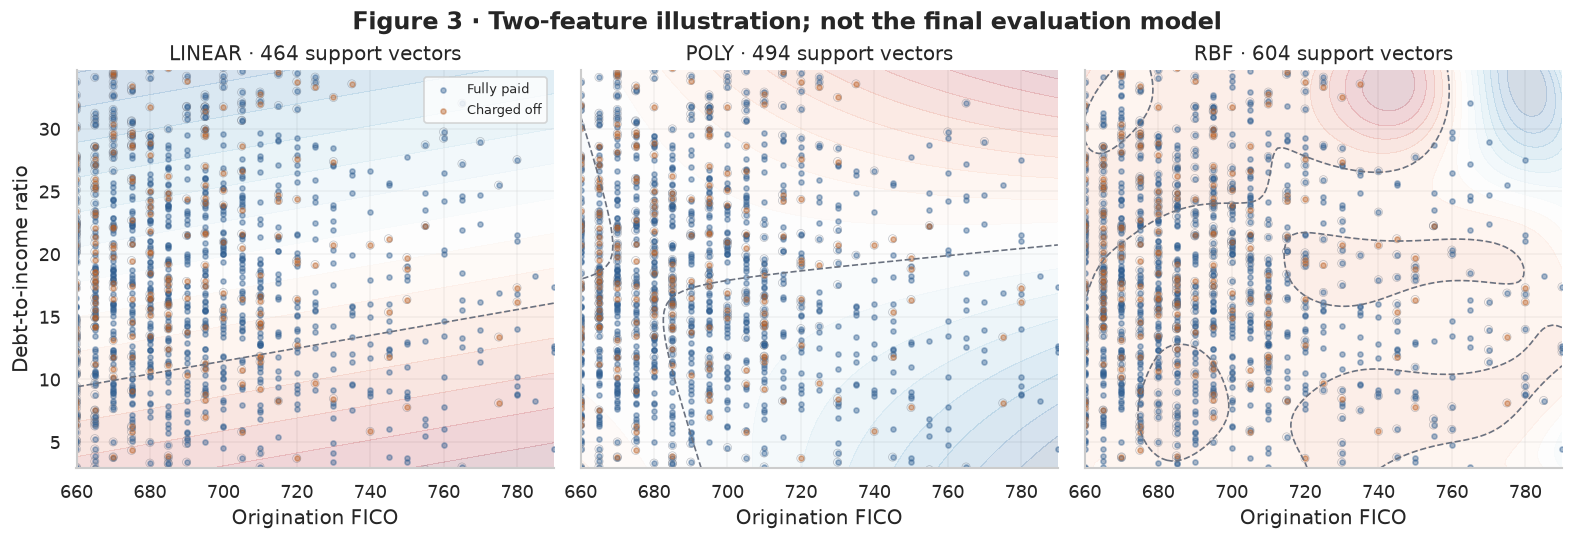

In [10]:
illustration=X_fit.sample(n=min(1200,len(X_fit)),random_state=SEED)[["fico_range_low","dti"]]
illustration_y=y_fit.loc[illustration.index]
f_low,f_high=illustration.fico_range_low.quantile([.02,.98])
d_low,d_high=illustration.dti.quantile([.02,.98])
gx,gy=np.meshgrid(np.linspace(f_low,f_high,100),np.linspace(d_low,d_high,100))
grid=pd.DataFrame({"fico_range_low":gx.ravel(),"dti":gy.ravel()})
fig,axes=plt.subplots(1,3,figsize=(13,4.4),layout="constrained",sharex=True,sharey=True)
for ax,kernel in zip(axes,["linear","poly","rbf"]):
    demo=Pipeline([("impute",SimpleImputer(strategy="median")),("scale",StandardScaler()),
        ("model",SVC(kernel=kernel,C=1,degree=2,gamma="scale",coef0=1,max_iter=50_000))]).fit(illustration,illustration_y)
    surface=demo.decision_function(grid).reshape(gx.shape)
    ax.contourf(gx,gy,surface,levels=16,cmap="RdBu_r",alpha=.18)
    levels=[level for level in [-1,0,1] if surface.min()<level<surface.max()]
    if levels: ax.contour(gx,gy,surface,levels=levels,colors=GRAY,linestyles=["solid" if v==0 else "dashed" for v in levels],linewidths=1)
    for value,color,label in [(0,BLUE,"Fully paid"),(1,ORANGE,"Charged off")]:
        mask=illustration_y.eq(value)
        ax.scatter(illustration.loc[mask,"fico_range_low"],illustration.loc[mask,"dti"],s=9,alpha=.42,color=color,label=label)
    support=illustration.iloc[demo.named_steps["model"].support_]
    ax.scatter(support.fico_range_low,support.dti,s=24,facecolors="none",edgecolors=GRAY,linewidths=.4,alpha=.45)
    ax.set(title=f"{kernel.upper()} · {len(support):,} support vectors",xlabel="Origination FICO",xlim=(f_low,f_high),ylim=(d_low,d_high))
axes[0].set_ylabel("Debt-to-income ratio");axes[0].legend(fontsize=8)
fig.suptitle("Figure 3 · Two-feature illustration; not the final evaluation model",fontweight="bold")
finish(fig,"figure_3_kernel_boundaries")

## 7. Choose Thresholds on Validation Data

After choosing the models, I use the validation data to compare possible decision thresholds. I test score quantiles along with the default threshold and keep the cutoff with the highest validation F1. If two cutoffs tie, I choose the higher one. This is the best cutoff among the values tested.

F1 combines precision and recall, which makes it useful for this comparison. It does not tell me which cutoff would save the most money. That would also depend on the cost of missed charge-offs, unnecessary reviews, and how many loans analysts can review.

The threshold plot shows the percentage of validation loans flagged for review. This makes the trade-off easier to understand when the raw SVM scores are close together. I keep each selected threshold fixed for the test evaluation and do not refit the models afterward.

Model,Threshold,Precision,Recall,F1,ROC-AUC,Average precision
Linear SVM,-1.000,0.207,0.863,0.334,0.534,0.217
RBF SVM,-0.995,0.277,0.570,0.372,0.621,0.295
Matched logistic,0.199,0.306,0.631,0.412,0.689,0.341


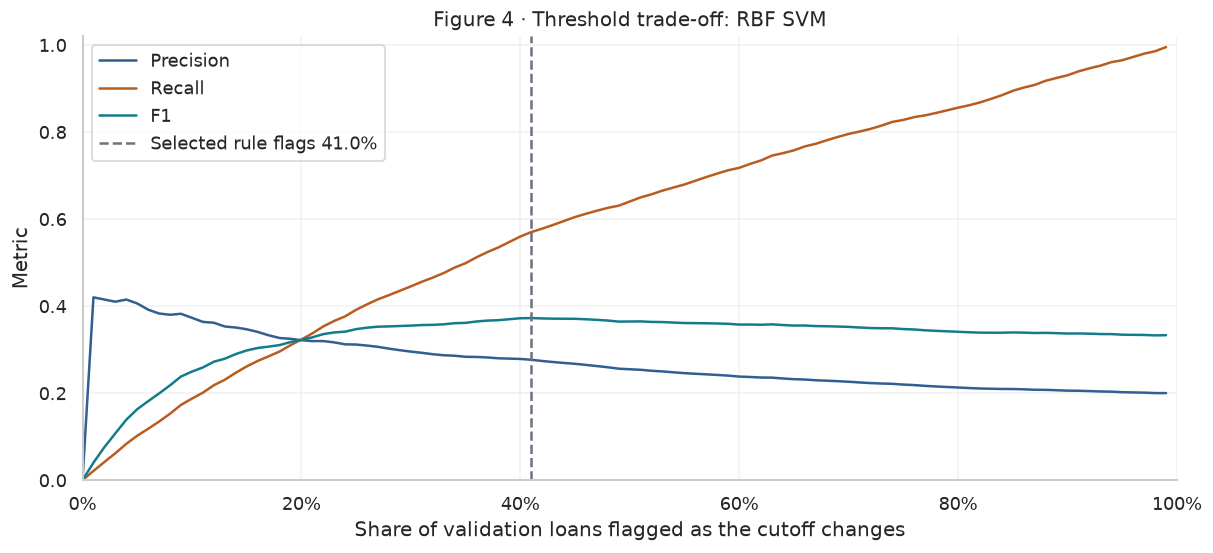

All model settings and thresholds are frozen.


In [11]:
def model_scores(name,model,frame):
    return model.predict_proba(frame)[:,1] if name=="Matched logistic" else model.decision_function(frame)
thresholds={};validation_tables={};validation_rows=[]
for name,model in fitted.items():
    default=.5 if name=="Matched logistic" else 0.
    score=model_scores(name,model,X_val)
    chosen,table=choose_threshold(y_val,score,default)
    thresholds[name]={"default":default,"selected":chosen}
    validation_tables[name]=table
    validation_rows.append(classification_metrics(name,y_val,score,chosen,"Validation-selected"))
validation_results=pd.DataFrame(validation_rows)
show_table(validation_results[["Model","Threshold","Precision","Recall","F1","ROC-AUC","Average precision"]])
validation_results.to_csv(OUTPUT_DIR/"validation_thresholds.csv",index=False)
view=validation_tables[selected_name].copy()
validation_score=model_scores(selected_name,fitted[selected_name],X_val)
view["Flagged share"]=[float(np.mean(validation_score>=t)) for t in view.Threshold]
view=view.sort_values("Flagged share")
chosen_share=float(np.mean(validation_score>=thresholds[selected_name]["selected"]))
fig,ax=plt.subplots(figsize=(10,4.5),layout="constrained")
for metric,color in [("Precision",BLUE),("Recall",ORANGE),("F1",TEAL)]:
    ax.plot(view["Flagged share"],view[metric],label=metric,color=color)
ax.axvline(chosen_share,color=GRAY,ls="--",label=f"Selected rule flags {chosen_share:.1%}")
ax.set(title=f"Figure 4 · Threshold trade-off: {selected_name}",xlabel="Share of validation loans flagged as the cutoff changes",
       ylabel="Metric",xlim=(0,1),ylim=(0,1.02),xticks=np.linspace(0,1,6),xticklabels=["0%","20%","40%","60%","80%","100%"])
ax.legend();finish(fig,"figure_4_validation_threshold")
print("All model settings and thresholds are frozen.")

## 8. Evaluate the Frozen Models

I compare the default threshold with the threshold selected on the validation data. Changing the threshold changes which loans are flagged, but it does not change their scores or ranking.

- **ROC-AUC** shows how well the scores rank charged-off loans above fully paid loans.
- **Average precision (AP)** summarizes precision across recall levels for the charged-off class.
- **Precision** tells me how many of the flagged loans actually charged off.
- **Recall** tells me how many of all the charged-off loans the model caught.

The majority baseline predicts `Fully Paid` for every loan and gives every loan the same score: the training charge-off rate. It can have high accuracy while missing every charged-off loan. I include false positives, missed charge-offs, and F1 so I can see that trade-off directly.

/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, U

Model,Rule,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,Average precision
Linear SVM,default,0.000,0.801,0.000,0.000,0.000,0.529,0.214
Linear SVM,selected,-1.000,0.309,0.203,0.847,0.328,0.529,0.214
RBF SVM,default,0.000,0.801,0.000,0.000,0.000,0.626,0.324
RBF SVM,selected,-0.995,0.611,0.273,0.573,0.369,0.626,0.324
Matched logistic,default,0.500,0.806,0.595,0.080,0.142,0.700,0.377
Matched logistic,selected,0.199,0.645,0.312,0.650,0.422,0.700,0.377
Majority baseline,default,0.500,0.801,0.000,0.000,0.000,0.500,0.199


Rule,TP,FP,FN,TN,Flagged share
default,0,0,1990,8010,0.000
selected,1140,3041,850,4969,0.418


Model,Split,ROC-AUC,Average precision
Linear SVM,Training,0.536,0.225
Linear SVM,Validation,0.534,0.217
Linear SVM,Test,0.529,0.214
RBF SVM,Training,0.868,0.716
RBF SVM,Validation,0.621,0.295
RBF SVM,Test,0.626,0.324
Matched logistic,Training,0.697,0.371
Matched logistic,Validation,0.689,0.341
Matched logistic,Test,0.700,0.377


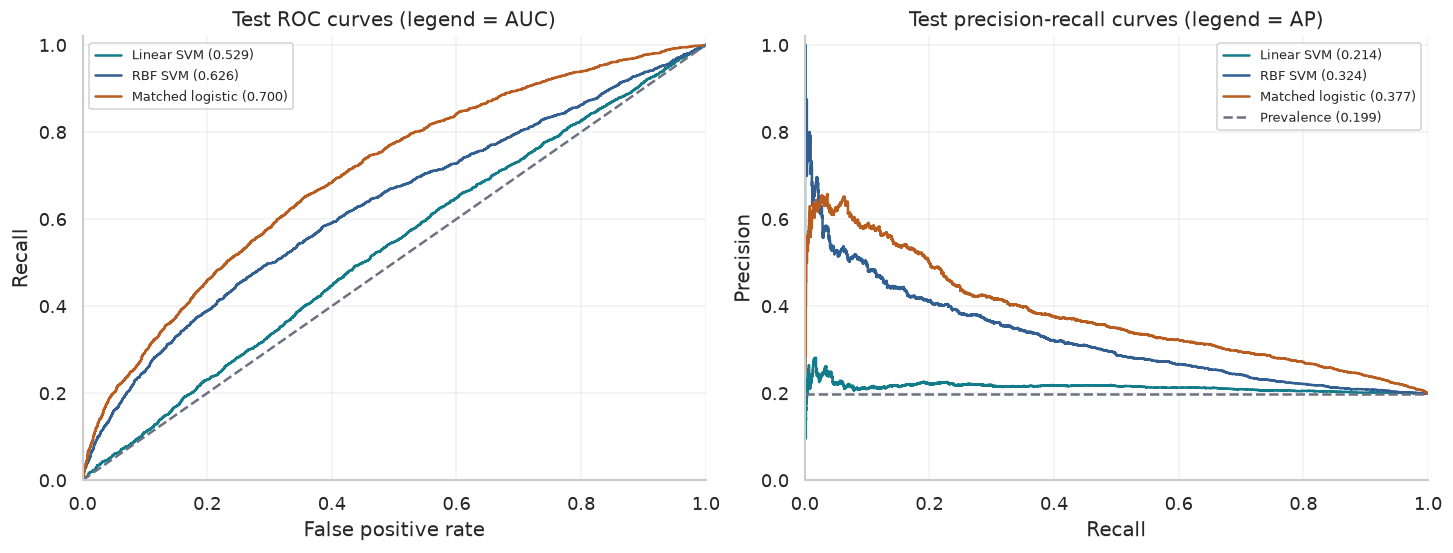

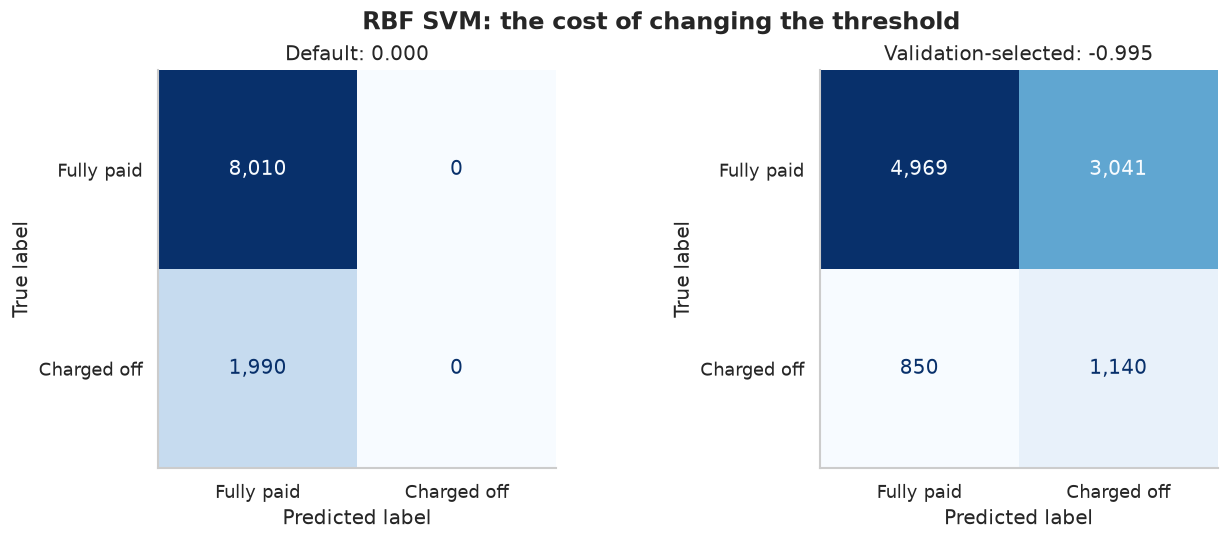

In [12]:
test_scores={};rows=[];gaps=[]
for name,model in fitted.items():
    score=model_scores(name,model,X_test);test_scores[name]=score
    for rule in ["default","selected"]:
        rows.append(classification_metrics(name,y_test,score,thresholds[name][rule],rule))
    for split,frame,target in [("Training",X_fit,y_fit),("Validation",X_val,y_val),("Test",X_test,y_test)]:
        split_score=model_scores(name,model,frame)
        gaps.append({"Model":name,"Split":split,"ROC-AUC":roc_auc_score(target,split_score),
            "Average precision":average_precision_score(target,split_score)})
rows.append(classification_metrics("Majority baseline",y_test,np.full(len(y_test),y_fit.mean()),.5,"default"))
test_results=pd.DataFrame(rows);gap_table=pd.DataFrame(gaps)
show_table(test_results[["Model","Rule","Threshold","Accuracy","Precision","Recall","F1","ROC-AUC","Average precision"]],3)
show_table(test_results.loc[test_results.Model.eq(selected_name),["Rule","TP","FP","FN","TN","Flagged share"]],3)
show_table(gap_table,3)
test_results.to_csv(OUTPUT_DIR/"test_metrics.csv",index=False)
gap_table.to_csv(OUTPUT_DIR/"generalization_scores.csv",index=False)
pd.DataFrame({"source_row":loans.loc[X_test.index,"source_row"].to_numpy(),"observed_charged_off":y_test.to_numpy(),
    "svm_decision_score":test_scores[selected_name],"selected_prediction":(test_scores[selected_name]>=thresholds[selected_name]["selected"]).astype(int)}).to_csv(OUTPUT_DIR/"test_predictions.csv",index=False)
plot_ranking(y_test,test_scores,"figure_5_test_ranking")
plot_confusions(y_test,test_scores[selected_name],0.,thresholds[selected_name]["selected"],selected_name,"figure_6_test_confusions")

## 9. What I Learned, Limits, and Next Steps

The biggest takeaway for me is that the more flexible model did not give me better results here. Cross-validation selected the **RBF SVM with C = 1 and gamma = scale**, but its test ROC-AUC was **0.626**, compared with **0.700** for logistic regression trained on the same 8,000 loans. The SVM's average precision was **0.324**, compared with **0.377** for logistic regression.

The RBF model also had a large gap between its training ROC-AUC of **0.868** and test ROC-AUC of **0.626**. That is a sign of overfitting in this run. It fit the training sample much better than it ranked the loans in validation and testing.

Changing the threshold made a big difference in which loans were caught. At the default score threshold of zero, the RBF model caught no charged-off loans. At the validation-selected threshold of approximately **-0.995**, it caught **1,140 of 1,990 charge-offs**, or **57.3%**. However, it also flagged **3,041 fully paid loans**. Precision was **27.3%**, and F1 was **0.369**. The negative threshold is valid because it is an SVM decision score, not a probability.

### Limits and next steps

These results come from an 8,000-loan training sample and a limited search of settings. No polynomial configuration passed all the convergence checks through the final training fit, so that kernel was not retained in the final comparison. I cannot use this run to claim that every SVM setup would perform worse than logistic regression.

I also reused the historical test split from Week 4. The sample only includes accepted loans with the two selected outcomes, so it does not establish performance for future applicants or rejected loans.

For Milestone One, I will compare this result with Week 6 after checking that the same loan rows were used. I also want to test later loans and choose a threshold using actual review capacity and the cost of the two types of errors.